In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Tentukan Path (sesuaikan dengan struktur folder Anda)
# Asumsi data Olist ada di folder ini
DATA_PATH = r'C:\FRAUD-Sinta2\Data\Olist'
OUTPUT_PATH = r'C:\FRAUD-Sinta2\Output'

# Konstanta
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Libraries imported and setup complete.")               

Libraries imported and setup complete.


In [2]:
try:
    df_orders = pd.read_csv(os.path.join(DATA_PATH, 'olist_orders_dataset.csv'))
    df_payments = pd.read_csv(os.path.join(DATA_PATH, 'olist_order_payments_dataset.csv'))
    print("Dataset Olist berhasil di-load.")
except FileNotFoundError:
    print(f"Error: Pastikan dataset Olist ada di folder: {DATA_PATH}")

# Ambil kolom yg relevan
df_orders = df_orders[['order_id', 'customer_id', 'order_purchase_timestamp']]
df_payments = df_payments[['order_id', 'payment_value']]

# Gabungkan (Merge)
# Kita lakukan 'left merge' untuk menyimpan order yg mungkin belum terbayar (amount=NaN)
df_merged = pd.merge(df_orders, df_payments, on='order_id', how='left')

# Ganti nama kolom
df_merged.rename(columns={
    'customer_id': 'user_id',
    'order_purchase_timestamp': 'timestamp',
    'payment_value': 'amount'
}, inplace=True)

print(f"Data Olist digabungkan. Shape: {df_merged.shape}")

Dataset Olist berhasil di-load.
Data Olist digabungkan. Shape: (103887, 4)


In [3]:
# 1. Konversi timestamp & sort
df_merged['timestamp'] = pd.to_datetime(df_merged['timestamp'])
df_merged.sort_values(by=['user_id', 'timestamp'], inplace=True)

# 2. Isi data NaN (order tanpa pembayaran)
# Kita asumsikan order tanpa pembayaran memiliki 'amount' = 0
df_merged['amount'].fillna(0, inplace=True)

# 3. Hapus duplikat (jika ada)
df_merged.drop_duplicates(inplace=True)

# 4. Buat dataset 'normal' kita
df_normal = df_merged.copy()

# 5. (BARU) Tambahkan kolom Tipe Anomali
# 0 = Transaksi Normal
df_normal['anomaly_type'] = 0
df_normal['Class'] = 0

print(f"Data Normal siap. Shape: {df_normal.shape}")
print(df_normal.head())

Data Normal siap. Shape: (103272, 6)
                               order_id                           user_id  \
71588  5f79b5b0931d63f1a42989eb65b9da6e  00012a2ce6f8dcda20d059ce98491703   
10466  a44895d095d7e0702b6a162fa2dbeced  000161a058600d5901f007fab4c27140   
68796  316a104623542e4d75189bb372bc5f8d  0001fd6190edaaf884bcaf3d49edf079   
45160  5825ce2e88d5346438686b0bba99e5ee  0002414f95344307404f0ace7a26f1d5   
6119   0ab7fb08086d4af9141453c91878ed7a  000379cdec625522490c315e70c7a9fb   

                timestamp  amount  anomaly_type  Class  
71588 2017-11-14 16:08:26  114.74             0      0  
10466 2017-07-16 09:40:32   67.41             0      0  
68796 2017-02-28 11:06:43  195.42             0      0  
45160 2017-08-16 13:09:20  179.35             0      0  
6119  2018-04-02 13:42:17  107.01             0      0  


C:\Users\yosua\AppData\Local\Temp\ipykernel_16084\1648275955.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_merged['amount'].fillna(0, inplace=True)


In [4]:
# Kita akan buat 3 tipe anomali
N_ANOMALIES = 300 # Jumlah sampel untuk setiap tipe anomali
print(f"Menginjeksi {N_ANOMALIES} sampel untuk setiap tipe anomali...")

# --- Tipe 1: Anomali Nilai (Value Anomaly) ---
# Transaksi dengan 'amount' 1000x lipat dari rata-rata
anom_idx_1 = np.random.choice(df_normal.index, N_ANOMALIES, replace=False)
df_anom_1 = df_normal.loc[anom_idx_1].copy()

avg_amount = df_normal['amount'].mean()
df_anom_1['amount'] = (avg_amount * 1000) + (np.random.rand(N_ANOMALIES) * 1000)
df_anom_1['anomaly_type'] = 1 # Tipe 1 = Nilai
df_anom_1['Class'] = 1
print("Anomali Tipe 1 (Nilai) dibuat.")

# --- Tipe 2: Anomali Waktu (Time Anomaly) ---
# Transaksi yang terjadi pada jam 'aneh' (misal: 03:00 - 04:00)
anom_idx_2 = np.random.choice(df_normal.index, N_ANOMALIES, replace=False)
df_anom_2 = df_normal.loc[anom_idx_2].copy()

# Buat timestamp baru di jam 3 pagi, tapi tanggalnya tetap
df_anom_2['timestamp'] = df_anom_2['timestamp'].apply(
    lambda x: x.replace(hour=3, minute=np.random.randint(0, 59))
)
df_anom_2['anomaly_type'] = 2 # Tipe 2 = Waktu
df_anom_2['Class'] = 1
print("Anomali Tipe 2 (Waktu) dibuat.")

# --- Tipe 3: Anomali Sekuensial (Sequential Anomaly) ---
# Ini adalah ANOMALI UTAMA untuk LSTM
# 5 transaksi beruntun (dalam 1 menit) oleh 1 user
print("Membuat Anomali Tipe 3 (Sekuensial)...")
df_anom_3_list = []
# Cari N_ANOMALIES user unik untuk dijadikan fraudster
fraudster_users = np.random.choice(df_normal['user_id'].unique(), N_ANOMALIES, replace=False)

for user in fraudster_users:
    # Ambil 1 transaksi normal dari user ini sebagai 'template'
    template_trx = df_normal[df_normal['user_id'] == user].sample(1)
    if template_trx.empty:
        continue
    
    start_time = pd.to_datetime(template_trx['timestamp'].iloc[0])
    
    for i in range(5): # Buat 5 transaksi beruntun
        new_trx = template_trx.copy()
        new_trx['amount'] = np.random.uniform(500, 5000) # Amount kecil
        # Transaksi terjadi dalam 1 menit (tambah 0-60 detik)
        new_trx['timestamp'] = start_time + pd.to_timedelta(np.random.randint(0, 60), unit='s')
        new_trx['anomaly_type'] = 3 # Tipe 3 = Sekuensial
        new_trx['Class'] = 1
        
        df_anom_3_list.append(new_trx)

df_anom_3 = pd.concat(df_anom_3_list)
print(f"Anomali Tipe 3 (Sekuensial) dibuat. Total {len(df_anom_3)} transaksi.")


Menginjeksi 300 sampel untuk setiap tipe anomali...
Anomali Tipe 1 (Nilai) dibuat.
Anomali Tipe 2 (Waktu) dibuat.
Membuat Anomali Tipe 3 (Sekuensial)...
Anomali Tipe 3 (Sekuensial) dibuat. Total 1500 transaksi.



Dataset Simulasi Final (V2) selesai dibuat!
Disimpan di: C:\FRAUD-Sinta2\Output\simulasi_data_final_v2.csv
Shape Total: (105372, 6)


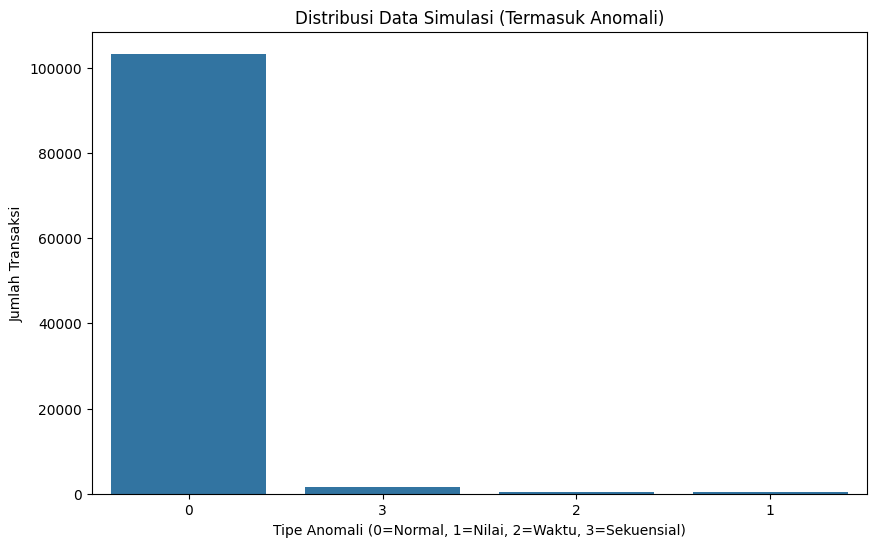


Distribusi Kelas:
Class
0    0.980071
1    0.019929
Name: proportion, dtype: float64


In [5]:
# 1. Gabungkan semua data
df_final = pd.concat([df_normal, df_anom_1, df_anom_2, df_anom_3])

# 2. Acak data (penting agar data fraud tersebar)
df_final = df_final.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

# 3. Simpan ke CSV
output_filename = os.path.join(OUTPUT_PATH, 'simulasi_data_final_v2.csv')
df_final.to_csv(output_filename, index=False)

print(f"\nDataset Simulasi Final (V2) selesai dibuat!")
print(f"Disimpan di: {output_filename}")
print(f"Shape Total: {df_final.shape}")

# 4. Tampilkan distribusi hasil
plt.figure(figsize=(10, 6))
sns.countplot(x='anomaly_type', data=df_final, order=df_final['anomaly_type'].value_counts().index)
plt.title('Distribusi Data Simulasi (Termasuk Anomali)')
plt.xlabel('Tipe Anomali (0=Normal, 1=Nilai, 2=Waktu, 3=Sekuensial)')
plt.ylabel('Jumlah Transaksi')
plt.show()

print("\nDistribusi Kelas:")
print(df_final['Class'].value_counts(normalize=True))